In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.DataFrame({
    "Date": [
        "2026-10-01", "2026-10-02", "2026-10-03",
        "2026-10-04", "2026-10-05", "2026-10-06",
        "2026-10-07", "2026-10-08", "2026-10-09"
    ],

    "Product": [
        "Laptop", "Mobile", "Headphones",
        "Laptop", "Mobile", "Keyboard",
        "Headphones", "Laptop", "Keyboard"
    ],

    "Category": [
        "Electronics", "Electronics", "Accessories",
        "Electronics", "Electronics", "Accessories",
        "Accessories", "Electronics", "Accessories"
    ],

    "Quantity": [2, 5, 10, 1, 3, 8, 6, 2, 4],

    "Unit_Price": [50000, 15000, 2000, 50000, 15000, 1500, 2000, 50000, 1500]
})

data["Sales"] = data["Quantity"] * data["Unit_Price"]

print(data)

data.to_csv("retail_sales.csv", index=False)

print("Dataset created successfully!")

         Date     Product     Category  Quantity  Unit_Price   Sales
0  2026-10-01      Laptop  Electronics         2       50000  100000
1  2026-10-02      Mobile  Electronics         5       15000   75000
2  2026-10-03  Headphones  Accessories        10        2000   20000
3  2026-10-04      Laptop  Electronics         1       50000   50000
4  2026-10-05      Mobile  Electronics         3       15000   45000
5  2026-10-06    Keyboard  Accessories         8        1500   12000
6  2026-10-07  Headphones  Accessories         6        2000   12000
7  2026-10-08      Laptop  Electronics         2       50000  100000
8  2026-10-09    Keyboard  Accessories         4        1500    6000
Dataset created successfully!


In [3]:
df = pd.read_csv("retail_sales.csv")

df["Date"] = pd.to_datetime(df["Date"])

df = df.drop_duplicates()
df = df.dropna()

# Calculate sales revenue
df["Sales"] = df["Quantity"] * df["Unit_Price"]

print("Data cleaned successfully!")

df

Data cleaned successfully!


,Date,Product,Category,Quantity,Unit_Price,Sales
0,2026-10-01,Laptop,Electronics,2,50000,100000
1,2026-10-02,Mobile,Electronics,5,15000,75000
2,2026-10-03,Headphones,Accessories,10,2000,20000
3,2026-10-04,Laptop,Electronics,1,50000,50000
4,2026-10-05,Mobile,Electronics,3,15000,45000
5,2026-10-06,Keyboard,Accessories,8,1500,12000
6,2026-10-07,Headphones,Accessories,6,2000,12000
7,2026-10-08,Laptop,Electronics,2,50000,100000
8,2026-10-09,Keyboard,Accessories,4,1500,6000


In [4]:
class RetailSalesAnalyzer:

    def __init__(self, filename):
        self.filename = filename
        self.df = pd.read_csv(filename)

        self.df["Date"] = pd.to_datetime(self.df["Date"])

        # Calculate sales if the column is missing
        if "Sales" not in self.df.columns:
            self.df["Sales"] = (
                self.df["Quantity"] * self.df["Unit_Price"]
            )

    def log_sale(self, product, category, quantity, unit_price):

        if quantity <= 0 or unit_price < 0:
            print("Invalid input!")
            return

        new_row = {
            "Date": pd.Timestamp.today(),
            "Product": product,
            "Category": category,
            "Quantity": quantity,
            "Unit_Price": unit_price,
            "Sales": quantity * unit_price
        }

        self.df = pd.concat(
            [self.df, pd.DataFrame([new_row])],
            ignore_index=True
        )

        self.df.to_csv(self.filename, index=False)

        print("Sale added successfully!")

    def calculate_metrics(self):

        print("Total Revenue:", self.df["Sales"].sum())

        print("Total Units Sold:", self.df["Quantity"].sum())

        print("Average Sale Value:", self.df["Sales"].mean())

        print("Total Transactions:", len(self.df))

    def filter_products(self, product):

        return self.df[
            self.df["Product"].str.lower() == product.lower()
        ]

    def filter_category(self, category):

        return self.df[
            self.df["Category"].str.lower() == category.lower()
        ]

    def generate_report(self):

        print("Retail Sales Report")
        print(self.df)

        print("\nSales Summary by Product:")

        print(
            self.df.groupby("Product")["Sales"].sum()
        )

        print("\nSales Summary by Category:")

        print(
            self.df.groupby("Category")["Sales"].sum()
        )

        print("\nQuantity Sold by Product:")

        print(
            self.df.groupby("Product")["Quantity"].sum()
        )

In [5]:
analyzer = RetailSalesAnalyzer("retail_sales.csv")

print("Retail Sales Analyzer created successfully!")

Retail Sales Analyzer created successfully!


In [6]:
analyzer.calculate_metrics()

Total Revenue: 420000
Total Units Sold: 41
Average Sale Value: 46666.666666666664
Total Transactions: 9


In [7]:
laptop_sales = analyzer.filter_products("Laptop")

print(laptop_sales)

        Date Product     Category  Quantity  Unit_Price   Sales
0 2026-10-01  Laptop  Electronics         2       50000  100000
3 2026-10-04  Laptop  Electronics         1       50000   50000
7 2026-10-08  Laptop  Electronics         2       50000  100000


In [8]:
sales = analyzer.df["Sales"].to_numpy()

print("Average Sales:", np.mean(sales))
print("Maximum Sale:", np.max(sales))
print("Minimum Sale:", np.min(sales))
print("Total Sales:", np.sum(sales))
print("Standard Deviation:", np.std(sales))

Average Sales: 46666.666666666664
Maximum Sale: 100000
Minimum Sale: 6000
Total Sales: 420000
Standard Deviation: 35393.031329156685


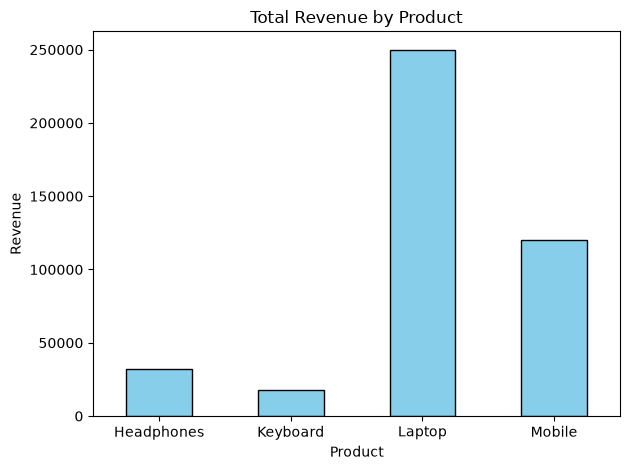

In [9]:
analyzer.df.groupby("Product")["Sales"].sum().plot(
    kind="bar",
    color="skyblue",
    edgecolor="black"
)

plt.title("Total Revenue by Product")
plt.xlabel("Product")
plt.ylabel("Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

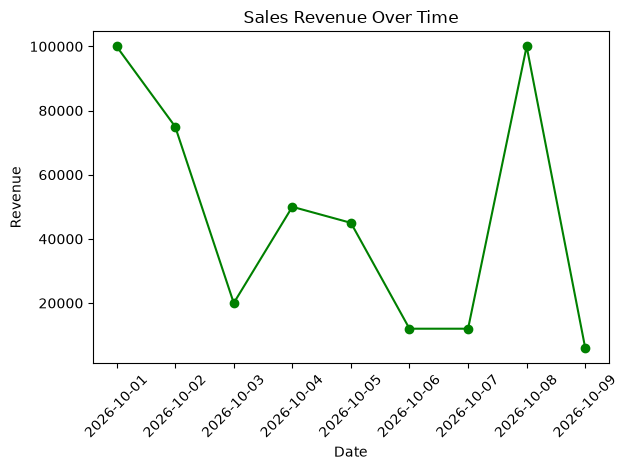

In [10]:
plt.plot(
    analyzer.df["Date"],
    analyzer.df["Sales"],
    marker="o",
    color="green"
)

plt.title("Sales Revenue Over Time")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

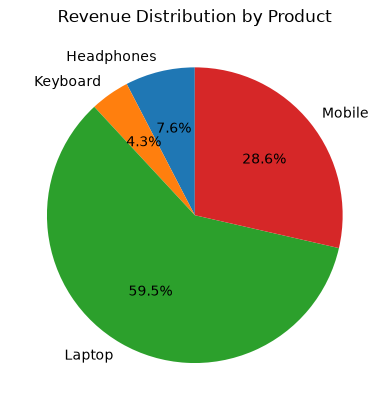

In [11]:
product_sales = analyzer.df.groupby("Product")["Sales"].sum()

plt.pie(
    product_sales,
    labels=product_sales.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Distribution by Product")
plt.show()

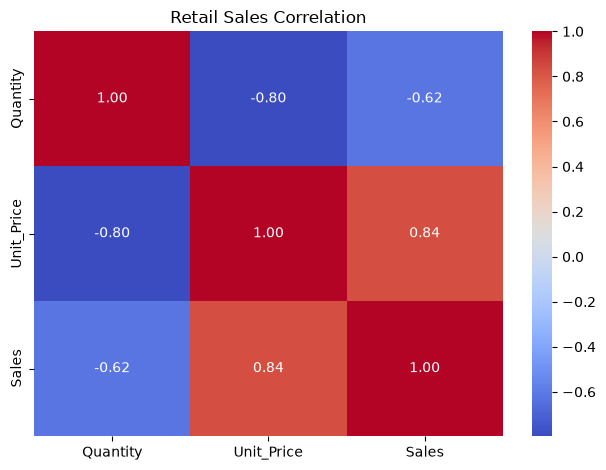

In [12]:
correlation = analyzer.df[
    ["Quantity", "Unit_Price", "Sales"]
].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Retail Sales Correlation")
plt.tight_layout()
plt.show()

In [13]:
analyzer.log_sale(
    product="Mouse",
    category="Accessories",
    quantity=5,
    unit_price=800
)

Sale added successfully!
